In [ ]:
import tensorflow as tf
import os

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [ ]:
import os
import tensorflow as tf

MODEL_PATH = "/content/agrovision_best_model.h5"

print("Model file exists:", os.path.exists(MODEL_PATH))

if os.path.exists(MODEL_PATH):
    print("Model size (MB):", round(
        os.path.getsize(MODEL_PATH) / (1024 * 1024), 2
    ))

    try:
        model = tf.keras.models.load_model(
            MODEL_PATH,
            compile=False
        )

        print("\nModel loaded successfully!")
        print("Input shape:", model.input_shape)
        print("Output shape:", model.output_shape)
        model.summary()

    except Exception as e:
        print("\nModel loading failed.")
        print("Error:", repr(e))
else:
    print("Please upload the model file first.")

Model file exists: True
Model size (MB): 19.7

Model loaded successfully!
Input shape: (None, 224, 224, 3)
Output shape: (None, 15)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,381,362 (16.71 MB)

 Trainable params: 331,791 (1.27 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
import os
import zipfile

zip_path = "/content/archive (2).zip"
extract_dir = "/content/agrovision_pa_data"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    if bad_file:
        raise RuntimeError(f"ZIP integrity check failed at: {bad_file}")

    z.extractall(extract_dir)

print("Extraction completed.")
print("Workspace:", extract_dir)
print("Top-level items:", os.listdir(extract_dir)[:20])

In [1]:
import os

for path in [
    "/content/archive (2).zip",
    "/content/agrovision_best_model.h5",
    "/content/agrovision_pa_data"
]:
    print(path, "exists:", os.path.exists(path))

/content/archive (2).zip exists: True
/content/agrovision_best_model.h5 exists: False
/content/agrovision_pa_data exists: False


In [2]:
import os
import zipfile

zip_path = "/content/archive (2).zip"
extract_dir = "/content/agrovision_pa_data"

# Verify the archive before extracting
assert os.path.isfile(zip_path), "Dataset ZIP is missing!"

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()

    if bad_file is not None:
        raise RuntimeError(f"Corrupted file inside ZIP: {bad_file}")

    print("ZIP integrity check passed.")
    print("Extracting dataset...")

    z.extractall(extract_dir)

print("Extraction completed.")
print("Top-level folders:", os.listdir(extract_dir)[:20])

ZIP integrity check passed.
Extracting dataset...
Extraction completed.
Top-level folders: ['PlantVillage', 'plantvillage']


In [3]:
import os

print("Dataset folder exists:",
      os.path.isdir("/content/agrovision_pa_data"))

print("Model exists:",
      os.path.isfile("/content/agrovision_best_model.h5"))

Dataset folder exists: True
Model exists: True


In [4]:
from pathlib import Path
from collections import Counter

ROOT = Path("/content/agrovision_pa_data")
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for top in sorted(ROOT.iterdir()):
    if not top.is_dir():
        continue

    print(f"\n{'='*60}")
    print("TOP-LEVEL FOLDER:", top.name)
    print("Path:", top)

    subfolders = sorted(p for p in top.iterdir() if p.is_dir())
    print("Immediate subfolders:", len(subfolders))

    for folder in subfolders[:25]:
        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )
        print(f"  {folder.name}: {count} images")

    total = sum(
        1 for p in top.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS
    )
    print("TOTAL images under this folder:", total)


TOP-LEVEL FOLDER: PlantVillage
Path: /content/agrovision_pa_data/PlantVillage
Immediate subfolders: 15
  Pepper__bell___Bacterial_spot: 997 images
  Pepper__bell___healthy: 1478 images
  Potato___Early_blight: 1000 images
  Potato___Late_blight: 1000 images
  Potato___healthy: 152 images
  Tomato_Bacterial_spot: 2127 images
  Tomato_Early_blight: 1000 images
  Tomato_Late_blight: 1909 images
  Tomato_Leaf_Mold: 952 images
  Tomato_Septoria_leaf_spot: 1771 images
  Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
  Tomato__Target_Spot: 1404 images
  Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
  Tomato__Tomato_mosaic_virus: 373 images
  Tomato_healthy: 1591 images
TOTAL images under this folder: 20638

TOP-LEVEL FOLDER: plantvillage
Path: /content/agrovision_pa_data/plantvillage
Immediate subfolders: 1
  PlantVillage: 20638 images
TOTAL images under this folder: 20638


In [5]:
from pathlib import Path
import tensorflow as tf
import numpy as np

# 1. Define the verified dataset and model paths
DATA_DIR = Path("/content/agrovision_pa_data/PlantVillage")
MODEL_PATH = "/content/agrovision_best_model.h5"

# 2. Read class folder names in alphabetical order
class_names = sorted(
    p.name for p in DATA_DIR.iterdir() if p.is_dir()
)

print("Number of classes:", len(class_names))
print("\nClass names and output indices:")

for index, name in enumerate(class_names):
    print(f"{index:2d}: {name}")

# 3. Load the saved model
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

print("\nModel input shape:", model.input_shape)
print("Model output shape:", model.output_shape)

# 4. Check compatibility
assert len(class_names) == 15, (
    f"Expected 15 classes, found {len(class_names)}"
)
assert model.output_shape[-1] == len(class_names), (
    "Model output count does not match the number of classes"
)

print("\nPASS: 15 dataset classes match 15 model outputs.")

Number of classes: 15

Class names and output indices:
 0: Pepper__bell___Bacterial_spot
 1: Pepper__bell___healthy
 2: Potato___Early_blight
 3: Potato___Late_blight
 4: Potato___healthy
 5: Tomato_Bacterial_spot
 6: Tomato_Early_blight
 7: Tomato_Late_blight
 8: Tomato_Leaf_Mold
 9: Tomato_Septoria_leaf_spot
10: Tomato_Spider_mites_Two_spotted_spider_mite
11: Tomato__Target_Spot
12: Tomato__Tomato_YellowLeaf__Curl_Virus
13: Tomato__Tomato_mosaic_virus
14: Tomato_healthy

Model input shape: (None, 224, 224, 3)
Model output shape: (None, 15)

PASS: 15 dataset classes match 15 model outputs.


In [6]:
import os
import splitfolders

SOURCE_DIR = "/content/agrovision_pa_data/PlantVillage"
OUTPUT_DIR = "/content/agrovision_pa_split"

assert os.path.isdir(SOURCE_DIR), "Source dataset not found!"
assert not os.path.exists(OUTPUT_DIR), (
    "PA split folder already exists. Stop and inspect it first."
)

splitfolders.ratio(
    SOURCE_DIR,
    output=OUTPUT_DIR,
    seed=42,
    ratio=(0.8, 0.2)
)

print("PA dataset split created.")
print("Training folder:", os.path.join(OUTPUT_DIR, "train"))
print("Validation folder:", os.path.join(OUTPUT_DIR, "val"))

ModuleNotFoundError: No module named 'splitfolders'

In [7]:
%pip install split-folders==0.5.1

In [8]:
import os
import splitfolders

SOURCE_DIR = "/content/agrovision_pa_data/PlantVillage"
OUTPUT_DIR = "/content/agrovision_pa_split"

assert os.path.isdir(SOURCE_DIR), "Source dataset not found!"
assert not os.path.exists(OUTPUT_DIR), (
    "PA split folder already exists. Stop and inspect it first."
)

splitfolders.ratio(
    SOURCE_DIR,
    output=OUTPUT_DIR,
    seed=42,
    ratio=(0.8, 0.2)
)

print("PA dataset split created.")

Copying files: 20639 files [00:19, 1050.00 files/s]

PA dataset split created.


In [9]:
import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.efficientnet import preprocess_input

DATA_SPLIT = "/content/agrovision_pa_split"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_dir = os.path.join(DATA_SPLIT, "train")
val_dir = os.path.join(DATA_SPLIT, "val")

assert os.path.isdir(train_dir), "Training directory missing"
assert os.path.isdir(val_dir), "Validation directory missing"

# Match the original notebook's preprocessing.
# Augmentation is configured for training, but we will not train.
train_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    fill_mode="nearest"
)

val_gen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

# Disable shuffling so predictions and true labels stay aligned.
train_data = train_gen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

val_data = val_gen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\nTraining images:", train_data.samples)
print("Validation images:", val_data.samples)
print("Training classes:", len(train_data.class_indices))
print("Validation classes:", len(val_data.class_indices))
print(
    "Class mappings identical:",
    train_data.class_indices == val_data.class_indices
)

Found 16504 images belonging to 15 classes.
Found 4134 images belonging to 15 classes.

Training images: 16504
Validation images: 4134
Training classes: 15
Validation classes: 15
Class mappings identical: True


130/130 ━━━━━━━━━━━━━━━━━━━━ 377s 3s/step

Validation accuracy: 0.7591

Classification report:

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.88      0.86      0.87       200
                     Pepper__bell___healthy       0.76      1.00      0.86       296
                      Potato___Early_blight       1.00      0.83      0.91       200
                       Potato___Late_blight       0.85      0.93      0.89       200
                           Potato___healthy       0.85      0.90      0.88        31
                      Tomato_Bacterial_spot       0.86      0.83      0.84       426
                        Tomato_Early_blight       1.00      0.12      0.21       200
                         Tomato_Late_blight       0.70      0.93      0.80       382
                           Tomato_Leaf_Mold       0.87      0.71      0.78       191
                  Tomato_Septoria_leaf_spot       0.5

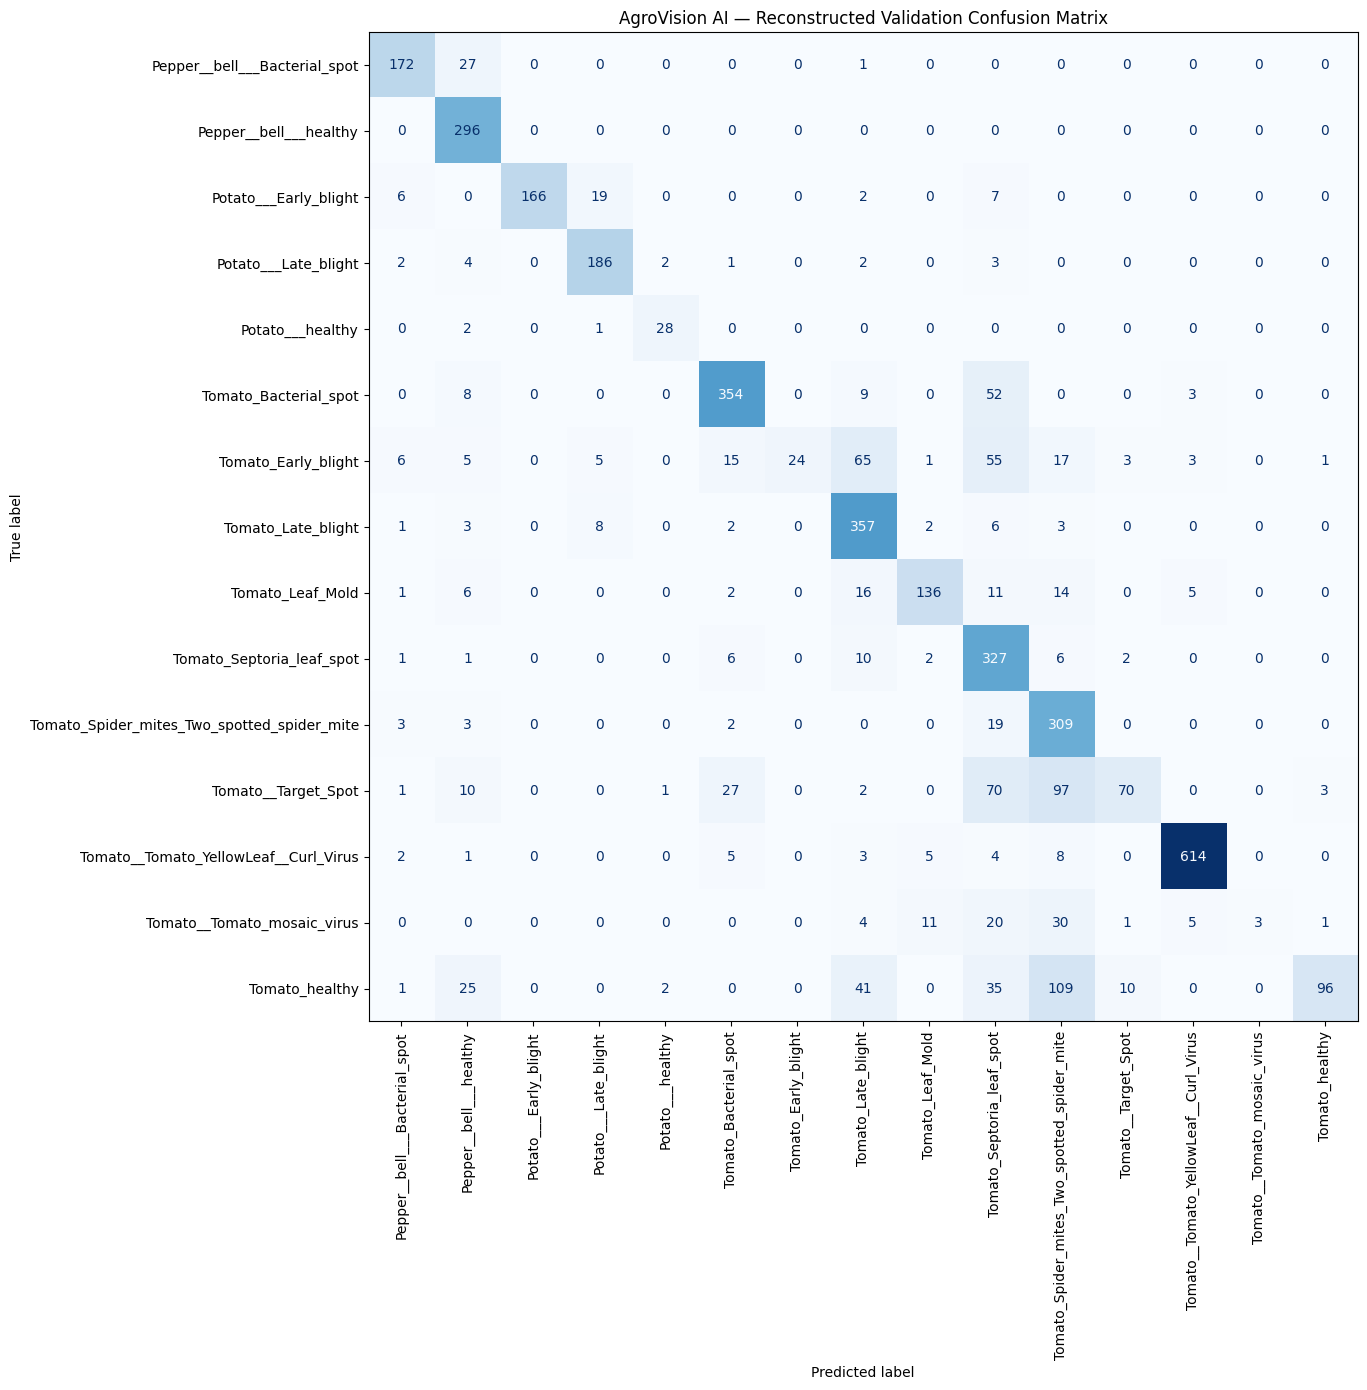


Results saved to: /content/agrovision_pa_results
Files: ['confusion_matrix.png', 'classification_report.txt', 'confusion_matrix.csv', 'classification_report.csv']


In [10]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Paths
MODEL_PATH = "/content/agrovision_best_model.h5"
RESULTS_DIR = "/content/agrovision_pa_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Load the saved model; do not retrain it
model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# Confirm model and generator compatibility
assert model.input_shape[1:] == (224, 224, 3)
assert model.output_shape[-1] == len(val_data.class_indices)

# Predict on the validation data in fixed order
val_data.reset()
probabilities = model.predict(val_data, verbose=1)

y_pred = np.argmax(probabilities, axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)

report_dict = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_text = classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
)

print(f"\nValidation accuracy: {accuracy:.4f}")
print("\nClassification report:\n")
print(report_text)

# Save results
pd.DataFrame(report_dict).transpose().to_csv(
    os.path.join(RESULTS_DIR, "classification_report.csv")
)

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
).to_csv(os.path.join(RESULTS_DIR, "confusion_matrix.csv"))

with open(
    os.path.join(RESULTS_DIR, "classification_report.txt"),
    "w",
    encoding="utf-8"
) as f:
    f.write(f"Validation accuracy: {accuracy:.6f}\n\n")
    f.write(report_text)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(16, 14))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
display.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False
)
plt.title("AgroVision AI — Reconstructed Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "confusion_matrix.png"),
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("\nResults saved to:", RESULTS_DIR)
print("Files:", os.listdir(RESULTS_DIR))

In [11]:
import shutil
import os

results_dir = "/content/agrovision_pa_results"
zip_path = "/content/agrovision_pa_results.zip"

shutil.make_archive(
    "/content/agrovision_pa_results",
    "zip",
    results_dir
)

print("Results ZIP created:", os.path.exists(zip_path))
print("Size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

Results ZIP created: True
Size (MB): 0.28


In [12]:
from google.colab import files
files.download("/content/agrovision_pa_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>